In [1]:
import sys
from pathlib import Path
import math
import importlib
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.load_metadata import load_metadata
from src.fonts import find_japanese_font

metadata = load_metadata()

# Each notebook initializes its own font configuration.
JP_FONT_PATH = None
jp_font = find_japanese_font(metadata["char"].unique(), JP_FONT_PATH)

if jp_font is None:
    print("No compatible Japanese font found. Image titles will be omitted.")
else:
    print(f"Japanese font: {jp_font.get_name()}")

metadata.head()

Japanese font: Hiragino Sans


,record_index,char,unicode,writer_id,source_file,image_path
0,0,ア,0x30a2,1001,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
1,1,ア,0x30a2,1002,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
2,2,ア,0x30a2,1003,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
3,3,ア,0x30a2,1004,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
4,4,ア,0x30a2,1005,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...


Katakana expected to be present : 46/46
Additional : ヰ, ヱ


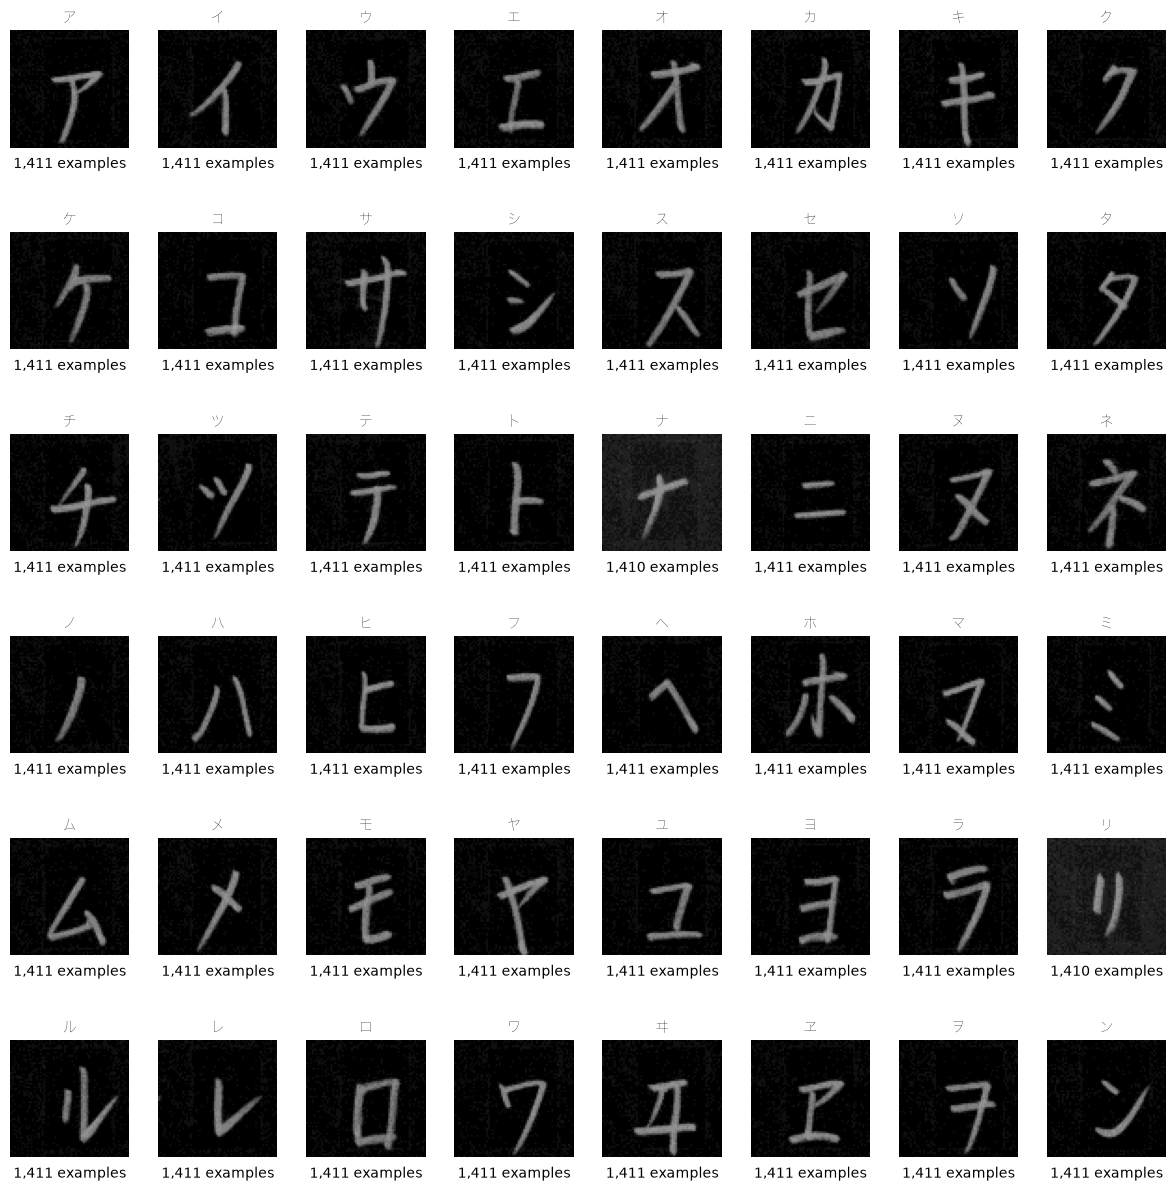

In [2]:
expected = set(
    "アイウエオ"
    "カキクケコ"
    "サシスセソ"
    "タチツテト"
    "ナニヌネノ"
    "ハヒフヘホ"
    "マミムメモ"
    "ヤユヨ"
    "ラリルレロ"
    "ワヲン"
)

present = set(metadata["char"].dropna())
missing = expected - present
extra = present - expected

print(f"Katakana expected to be present : {len(expected & present)}/46")
print("Additional :", ", ".join(sorted(extra)) or "aucun")

if missing:
    raise ValueError(
        f"Missing Katakana : {', '.join(sorted(missing))}"
    )

font = jp_font

groups = list(metadata.groupby("char", sort=False))
ncols = 8
nrows = math.ceil(len(groups) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, nrows * 2),
    squeeze=False
)

for ax in axes.flat:
    ax.set_axis_off()

for ax, (character, group) in zip(axes.flat, groups):
    row = group.sample(n=1, random_state=23).iloc[0]

    with Image.open(row["image_path"]) as image:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    if font is not None:
        ax.set_title(character, fontproperties=font)

    ax.text(
        0.5, -0.08,
        f"{len(group):,} examples",
        transform=ax.transAxes,
        ha="center",
        va="top"
    )

plt.tight_layout(h_pad=3)
plt.show()

In [7]:
from src.split_dataset import split

#training = 0.7
#validation = 0.15
#test = 0.15

df_train, df_valid, df_test = split(metadata)

In [11]:
splits = {
    "Training": df_train,
    "Validation": df_valid,
    "Test": df_test,
}

expected_classes = set(metadata["char"].unique())

for name, df in splits.items():
    print(
        f"{name}: {len(df):,} images, "
        f"{df['writer_id'].nunique()} writers, "
        f"{df['char'].nunique()} characters"
    )

    missing = expected_classes - set(df["char"].unique())
    assert not missing, f"{name}: missing characters : {missing}"

assert len(expected_classes) == 48, "The dataset should contain 48 characters."

train_writers = set(df_train["writer_id"])
valid_writers = set(df_valid["writer_id"])
test_writers = set(df_test["writer_id"])

assert not train_writers & valid_writers, "One or some writers are both in train and validation."
assert not train_writers & test_writers, "One or some writers are both in train and test."
assert not valid_writers & test_writers, "One or some writers are both in validation and test."
#all should be 0

all_paths = [
    path
    for df in splits.values()
    for path in df["image_path"]
]

assert len(all_paths) == len(metadata), "The total number of image has changed"
assert len(set(all_paths)) == len(all_paths), "Some images are duplicates."

print("\n All done")

Training: 47,375 images, 987 writers, 48 characters
Validation: 10,128 images, 211 writers, 48 characters
Test: 10,223 images, 213 writers, 48 characters

 All done


,record_index,char,unicode,writer_id,source_file,image_path
9,9,ア,0x30a2,1010,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
21,21,ア,0x30a2,1022,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
24,24,ア,0x30a2,1025,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
28,28,ア,0x30a2,1030,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
29,29,ア,0x30a2,1031,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
...,...,...,...,...,...,...
67683,4190,ン,0x30f3,2918,ETL1C_13,/Users/nailito/Desktop/Data/katakana-recogniti...
67688,4195,ン,0x30f3,2923,ETL1C_13,/Users/nailito/Desktop/Data/katakana-recogniti...
67691,4198,ン,0x30f3,2926,ETL1C_13,/Users/nailito/Desktop/Data/katakana-recogniti...
67693,4200,ン,0x30f3,2928,ETL1C_13,/Users/nailito/Desktop/Data/katakana-recogniti...


(10271, 6)

(47375, 6)

(67726, 6)